In [5]:
from importlib.metadata import version

import matplotlib
import tiktoken
import torch

print("matplotlib version:", version("matplotlib"))
print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

matplotlib version: 3.11.0
torch version: 2.13.0
tiktoken version: 0.13.0


In [6]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [7]:
import torch
import torch.nn as nn

#Dummy是假的意思,这个用于跑通早期的流程用的
class DummyGPTModel(nn.Module):
    def __init__(self,cfg):
        #用父类的初始化参数
        super().__init__()
        #词嵌入查找表
        self.tok_emb = nn.Embedding(cfg['vocab_size'],cfg['emb_dim'])
        #位置嵌入查找表 直接和词嵌入做加法
        self.pos_emb = nn.Embedding(cfg['context_length'],cfg['emb_dim'])
        self.drop_emb = nn.Dropout(cfg['drop_rate'])

        #创建12个块对象,传递给Sequential,变成一个顺序容器
            #知道将一层的输出作为下一层的输入
            #*解包吧每一层作为一个参数,在函数定义上是打包成一个元组
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg['n_layers'])])
        #归一化层
        self.final_norm = DummyLayerNorm(cfg['emb_dim'])
        #全连接层重新放大回以前的词典维度,选输出词
        self.out_head = nn.Linear(
            cfg['emb_dim'],cfg['vocab_size'],bias = False
        )

    def forward(self,in_idx):
        #数据的批大小和token长度(输入词元id)
        batch_size,seq_len = in_idx.shape
        #查词表,得到词嵌入
        tok_embeds = self.tok_emb(in_idx)
        #得到位置向量(外部有批次其实是矩阵)
        #位置的嵌入矩阵也是可以学习的,也是通过索引提取向量
            #若提取的词少,的确只有前几个提取的词对应的可以得到训练,哪怕上限是1014,取5个只训练前5个
        #arange的参数device是防止设备不一致,需要和in_dex(输入索引)的设备对齐
        pos_embeds = self.pos_emb(torch.arange(seq_len,device = in_idx.device))
        #用广播规则相加
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        #除了out_head这一步,上面的输入输出形状都一样,所以模型可以跑通
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):
    def __init__(self,cfg):
        super().__init__()

    def forward(self,x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self,normalized_shape,eps = 1e-5):
        super().__init__()

    def forward(self,x):
        return x

In [8]:
import tiktoken

tokenizer = tiktoken.get_encoding('gpt2')

batch = []

txt1 = 'Every effort moves you'
txt2 = 'Every day holds a'

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
#第一个参数需要是序列容器(容器不能是tensor),包含必须是tensor
batch = torch.stack(batch,dim = 0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [9]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)

logits = model(batch)
print('Output shape:',logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6754, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


In [10]:
torch.manual_seed(123)

batch_example = torch.randn(2,5)

layer = nn.Sequential(nn.Linear(5,6),nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [11]:
mean = out.mean(dim = -1,keepdim = True)
var= out.var(dim = -1,keepdim = True)

print(mean)
print(var)

tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [12]:
out_norm = (out - mean) / torch.sqrt(var)

print(out_norm)

tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)


In [13]:
mean = out_norm.mean(dim = -1,keepdim = True)
var = out_norm.var(dim = -1,keepdim = True)

print(mean)
print(var)

tensor([[-5.9605e-08],
        [ 1.9868e-08]], grad_fn=<MeanBackward1>)
tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [15]:
class LayerNorm(nn.Module):
    def __init__(self,emb_dim):
        super().__init__()
        self.eps = 1e-5
        #这个只是初始化,后面是可以学习的,所以用Parameter套起来
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self,x):
        mean = x.mean(dim = -1,keepdim = True)
        #unbiased是不用统计学上的除以n - 1 ,用n.对齐原transformer架构,后面也可以兼容
            #实际上参数量太大,n和n-1几乎没有区别
        var = x.var(dim = -1,keepdim = True,unbiased = False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)

        #这里的不是@是*,用了广播的规则
        return self.scale * norm_x + self.shift

In [21]:
ln = LayerNorm(emb_dim = 5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim = -1,keepdim = True)
var = out_ln.var(dim = -1,unbiased = False,keepdim = True)

print(mean)
print(var)

tensor([[-2.9802e-08],
        [ 0.0000e+00]], grad_fn=<MeanBackward1>)
tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [22]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self,x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x,3))
        ))

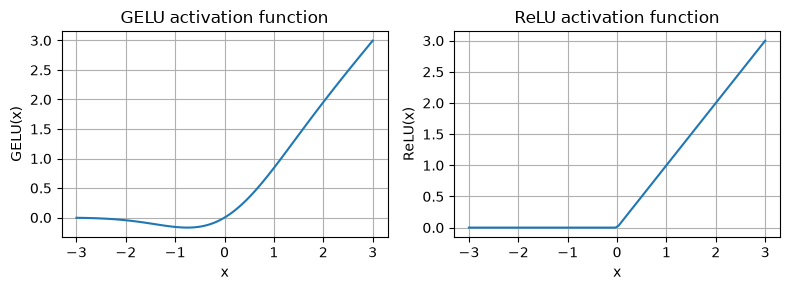

In [25]:
import matplotlib.pyplot as plt

gelu,relu = GELU(),nn.ReLU()

x = torch.linspace(-3,3,100)
y_gelu,y_relu = gelu(x),relu(x)

plt.figure(figsize = (8,3))

for i,(y,label) in enumerate(zip([y_gelu,y_relu],['GELU','ReLU']),1):
    plt.subplot(1,2,i)
    plt.plot(x,y)
    plt.title(f'{label} activation function')
    plt.xlabel('x')
    plt.ylabel(f'{label}(x)')
    plt.grid(True)

plt.tight_layout()
plt.show()

In [32]:
class FeedForward(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.layers = nn.Sequential(
            #升维度是为了提升GELU捕捉的细节
            #初始化一个Linear的类,里面的数值是随机的
            nn.Linear(cfg['emb_dim'],4*cfg['emb_dim']),
            GELU(),
            nn.Linear(4*cfg['emb_dim'],cfg['emb_dim']),
        )

    def forward(self,x):
        return self.layers(x)

In [33]:
print(GPT_CONFIG_124M['emb_dim'])

768


In [34]:
ffn = FeedForward(GPT_CONFIG_124M)

x = torch.rand(2,3,768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


In [49]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self,layer_sizes,use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0],layer_sizes[1]),GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1],layer_sizes[2]),GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2],layer_sizes[3]),GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3],layer_sizes[4]),GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4],layer_sizes[5]),GELU())
        ])

    def forward(self,x):
        for layer in self.layers:
            layer_output = layer(x)

            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output

        return x

In [50]:
def print_gradients(model,x):
    output = model(x)
    target = torch.tensor([[0.]])

    loss = nn.MSELoss()
    loss = loss(output,target)

    loss.backward()

    for name,param in model.named_parameters():
        if 'weight' in name:
            #item将一个元素的torch转变为python标量
            print(f'{name} has gradient mean of {param.grad.abs().mean().item()}')

In [52]:
layer_sizes = [3,3,3,3,3,1]

sample_input = torch.tensor([[1.,0.,-1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes , use_shortcut = False
)
print_gradients(model_without_shortcut,sample_input)

layers.0.0.weight has gradient mean of 0.00020173584925942123
layers.1.0.weight has gradient mean of 0.00012011158833047375
layers.2.0.weight has gradient mean of 0.0007152041071094573
layers.3.0.weight has gradient mean of 0.0013988735154271126
layers.4.0.weight has gradient mean of 0.005049645435065031


In [53]:
layer_sizes = [3,3,3,3,3,1]

sample_input = torch.tensor([[1.,0.,-1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes , use_shortcut = True
)
print_gradients(model_without_shortcut,sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694106817245483
layers.2.0.weight has gradient mean of 0.32896992564201355
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258540630340576


In [62]:
from previous_chapters import MultiHeadAttention

class TransformerBlock(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in = cfg['emb_dim'],
            d_out = cfg['emb_dim'],
            context_length = cfg['context_length'],
            num_heads = cfg['n_heads'],
            dropout = cfg['drop_rate'],
            qkv_bias = cfg['qkv_bias'])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg['emb_dim'])
        self.norm2 = LayerNorm(cfg['emb_dim'])
        #这样命名表示了这个是和shortcut一起用的
        self.drop_shortcut = nn.Dropout(cfg['drop_rate'])

    def forward(self,x):
        #注意力层添加快捷链接
        shortcut = x
        #前层归一化,效果更好
        x = self.norm1(x)
        x = self.att(x)
        x =self.drop_shortcut(x)
        x = x + shortcut

        #前馈层添加快捷链接
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x

In [63]:
torch.manual_seed(123)

x = torch.rand(2,4,768)
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print('Input shape',x.shape)
print('Output shape',output.shape)

Input shape torch.Size([2, 4, 768])
Output shape torch.Size([2, 4, 768])


In [65]:
class GPTModel(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg['vocab_size'],cfg['emb_dim'])
        self.pos_emb = nn.Embedding(cfg['context_length'],cfg['emb_dim'])
        self.drop_emb = nn.Dropout(cfg['drop_rate'])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg['n_layers'])])
        self.final_norm = LayerNorm(cfg['emb_dim'])
        self.out_head = nn.Linear(
            cfg['emb_dim'],cfg['vocab_size'],bias = False
        )

    def forward(self,in_idx):
        batch_size,seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len,device = in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [102]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

out = model(batch)
print('Input batch:\n',batch)
print('\nOutput shape',out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape torch.Size([2, 4, 50257])
tensor([[[-0.1291,  0.3885,  0.1057,  ...,  0.0180,  0.2309, -0.3901],
         [-0.2870, -0.0278, -0.3349,  ..., -0.0724,  0.1030, -0.3322],
         [-0.6001, -0.2720,  0.3672,  ...,  0.0804,  0.6928,  0.0880],
         [-1.3517, -0.3163,  0.2312,  ...,  0.3396, -0.0351,  0.3853]],

        [[-0.1893,  0.3246, -0.1917,  ..., -0.2170,  0.2229, -0.6889],
         [ 0.0024, -0.1743, -0.2006,  ...,  0.0684, -0.9490, -0.8778],
         [-0.0397,  0.0353,  0.2041,  ..., -0.3985,  0.1638, -0.2869],
         [-0.7979,  0.2167, -0.0873,  ...,  0.9055, -0.4025, -0.0753]]],
       grad_fn=<UnsafeViewBackward0>)


In [67]:
#sum接收迭代器之后会边输入边算
total_params = sum(p.numel() for p in model.parameters())
print(f'Total number of parameters: {total_params:,}')

Total number of parameters: 163,009,536


In [68]:
print('Token embedding layer shape:',model.tok_emb.weight.shape)
print('Output layer shape:',model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


In [69]:
total_params_gpt2 = total_params - sum(p.numel() for p in model.out_head.parameters())
print(total_params_gpt2)

124412160


In [72]:
#exercise4.1

In [73]:
att_params = sum(p.numel() for p in block.att.parameters())
print(f'attention number of parameters: {att_params:,}')

attention number of parameters: 2,360,064


In [74]:
ff_params = sum(p.numel() for p in block.ff.parameters())
print(f'Feedforward number of parameters: {ff_params:,}')

Feedforward number of parameters: 4,722,432


In [75]:
total_size_bytes = total_params * 4

total_size_mb = total_size_bytes / (1024 * 1024)

print(f'Total size of the model: {total_size_mb:.2f} MB')

Total size of the model: 621.83 MB


In [76]:
#exercise4.2

In [77]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

In [78]:
def get_config(base_config,model_name = 'small'):
    config = base_config

    if model_name == 'small':
        config['emb_dim'] = 768
        config['n_layers'] = 12
        config['n_heads'] = 12

    elif model_name == 'medium':
        config['emb_dim'] = 1024
        config['n_layers'] = 24
        config['n_heads'] = 16

    elif model_name == 'large':
        config['emb_dim'] = 1280
        config['n_layers'] = 36
        config['n_heads'] = 20

    elif model_name == 'xl':
        config['emb_dim'] = 1600
        config['n_layers'] = 48
        config['n_heads'] = 25

    return config

In [84]:
for config_name in ['small','medium','large','xl']:
    config = get_config(GPT_CONFIG_124M,config_name)
    model = GPTModel(config)

    parameters_num_f = sum(p.numel() for p in model.parameters())
    parameters_num = parameters_num_f - sum(p.numel() for p in model.out_head.parameters())
    parameters_size = (parameters_num * 4) / (1024*1024*1024)
    
    print(f'Model size is {config_name}')
    print(f'Parameters:{parameters_num}')
    print(f'Parameters size:{parameters_size:.2f} Gb')
    print('\n')
    

Model size is small
Parameters:124412160
Parameters size:0.46 Gb


Model size is medium
Parameters:354749440
Parameters size:1.32 Gb


Model size is large
Parameters:773891840
Parameters size:2.88 Gb


Model size is xl
Parameters:1557380800
Parameters size:5.80 Gb




In [103]:
#idx是当前文本索引数组
def generate_text_simple(model,idx,max_new_tokens,context_size):
    for _ in range(max_new_tokens):
        #最后的context_size个才可以输入
        #condition,表示条件上下文
        idx_cond = idx[:, -context_size:]

        #启用不计算梯度的方式
        with torch.no_grad():
            logits = model(idx_cond)

        #只关注输出内容,这个操作还会降维
        logits = logits[:,-1,:]

        probas = torch.softmax(logits,dim = -1)

        idx_next = torch.argmax(probas,dim = -1,keepdim = True)

        #将计算出来的idx添加到之前的索引组中
        idx = torch.cat((idx,idx_next),dim = 1)

    return idx

In [104]:
start_context = 'Hello, I am'

encoded = tokenizer.encode(start_context)
print('encoded:',encoded)

#因为第一维度是批大小,所以在第0维度添加大小为1的维度
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print('encoded_tensor.shape:',encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [105]:
#切换到评估模式,停用dropout
model.eval()

out = generate_text_simple(
    model = model,
    idx = encoded_tensor,
    max_new_tokens = 6,
    context_size = GPT_CONFIG_124M['context_length']
)

print('Output:',out)
print('Output length:',len(out[0]))

Output: tensor([[15496,    11,   314,   716, 25307,  7702, 20644, 13679, 12023, 29430]])
Output length: 10


In [106]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am 164 radicalBrown!' beef KR


In [107]:
#exercise4.3

In [108]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate_emb":0.1, 
    "drop_rate_attn":0.1, 
    "drop_rate_shortcut":0.1, 
    "qkv_bias": False
}

In [115]:
import torch.nn as nn
from gpt import MultiHeadAttention,LayerNorm,FeedForward

class TransformerBlock(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in = cfg['emb_dim'],
            d_out = cfg['emb_dim'],
            context_length = cfg['context_length'],
            num_heads = cfg['n_heads'],
            dropout = cfg['drop_rate_attn'],
            qkv_bias = cfg['qkv_bias'])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg['emb_dim'])
        self.norm2 = LayerNorm(cfg['emb_dim'])
        self.drop_shortcut = nn.Dropout(cfg['drop_rate_shortcut'])

    def forward(self,x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x

class GPTModel(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg['vocab_size'],cfg['emb_dim'])
        self.pos_emb = nn.Embedding(cfg['context_length'],cfg['emb_dim'])
        self.tok_emb = nn.Dropout(cfg['drop_rate_emb'])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg['n_layers'])])

        self.final_norm = LayerNorm(cfg['emb_dim'])
        self.out_head = nn.Linear(cfg['emb_dim'],cfg['vocab_size'],bias = False)

    def forward(self,in_idx):
        batch_size,seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len,device = in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [116]:
import torch

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)